We're going to have a practical code oriented look at understanding the Transformer architecture from the [Attention is All you Need](https://proceedings.neurips.cc/paper/2017/hash/3f5ee243547dee91fbd053c1c4a845aa-Abstract.html) paper. There are already very good articles on this such as [The Annotated Transformer](https://nlp.seas.harvard.edu/annotated-transformer/), albeit for pytorch, this  is going to be in jax and related libraries. The code is more exploratory and assumes basic understanding of jax or any Tensor processing library, such as pytorch.

In [1]:
import jax
from jax import numpy as jnp
import numpy as np
import flax.linen as nn
import matplotlib.pyplot as plt

## What is Transformer? 

Transformer is an Encoder-Decoder based neural network model architecture, which processes sequences. One class of its predecessors, recurrent networks, e.g. [RNN](https://www.osti.gov/biblio/6910294) and [LSTM](https://dl.acm.org/doi/10.1162/neco.1997.9.8.1735) were called seq2seq or sequence to sequence networked because they could take one sequence $X$ as input and map it to another sequence (the target) $Y$. In a typical sequence to sequence matching task, both the input and the target sequence can be of different lengths. Meaning, they do not have be a 1:1 match in size. So, $X$ can have $n$ elements and $Y$ can have $m$ elements. 

Seq2Seq Models are very popular and are also very effective in applications such as Speech Recognition (speech to text) and Synthesis (text to speech), Machine Translation (Dutch to English) etc. There is another textbook term for these models, sequence transduction models. Before transformers, successful (at their respective tasks) sequence transduction models were either based on recurrent or [convolution based architectures](https://aclanthology.org/W18-5408/). 

### Attention



When we are mapping one sequence to another, we are actually looking for some dependency in between the elements of the sequences. In sequence transduction, this dependency is learnt as a function. It can have different names based on the problem domain, e.g. alignment function in machine translation. Question is, how do we define this function? 

[Attention](https://iclr.cc/archive/www/lib/exe/fetch.php%3Fmedia=iclr2015:bahdanau-iclr2015.pdf) is one such dependency function which creates a learnt dependency representation from two sequences. Mathematically defined, a general form of attention would look like this.

We have a source sequence $X = <x_1, x_2, ..... x_n >$ and a target sequence $Y = <y_1, y_2, .... y_n >$, where $n$ and $m$ are their respective lengths. Through attention function $A(X, Y)$ we would like to know the probability of an element in $X$ having a dependency with another element in $Y$. So attention gives us a probability based representation of the depdendencies between the elements of two sequences. 

Let's try to understand attention from a more general perspective. What we are asking is that we would like to search for a dependency function between two sequences but we do not have the information on the search space. Instead, we have the two sequences. So what can we do to accomplish this search? In other words, we know the purpose of the search space and what kind of information it should contain but not the contents of it. 

Now we formalise this search with 3 terms. Query($Q$), Key($K$) and Values($V$). In simple terms, query is, our search query, or what we're looking for. Keys are information which are available to us, and values are the content that gets retrieved and aggregated when a key is selected. Now earlier, we said that we do not know the contents of the search space or this setup. Then how do we know what keys we have for a query? The answer is that we learn them, or give them some parameters which we train on some task specific data.

Perhaps we can explain this easier with a practical example. Let's say that we would like to know the dependencies between the words of these two sentences, one in German, the other in English.

- German: Der Flughafen ist nur einen Katzensprung von hier entfernt.
- English: The airport is only at a stone's throw from here.

Now, computers don't understand raw text, which otherwise would've saved us a lot of work building string and text processing algorithms, so we create some representation from the word using numbers and some function which the computers can comprehend. We will come back to these functions a bit later when we describe Transformer in detail but for now, we need to focus on attention. 

Let's say that German is our source sequence and English the target one, and we denote them again, with $X$ and $Y$ and let's assume that $X$ and $Y$ already have some numeric representation of these two sentences. What we now would like to know is, what are the dependencies between the German words and the English words. And our search query for the two sequence is:

```bash
If I was given the words from this English sentence, how would I know which German words they relate to? 
```

In terms of the formalism we defined above, our query comes from the target words, and we would be looking for keys in the source sequence. What about the values then? You might have noticed by now that this is more of a translation task, and we're looking for the alignment, hence, values will come from the German words to carry the information that gets aggregated.

Like we said, we will need to parameterise $Q$, $K$, and $V$. So from $Y$ (the target, English), we first create $Q$ via a linear projection.
$$Q = Linear(Y)$$

Now since keys come from $X$ (the source, German)
$$K = Linear(X)$$

And values?
$$V = Linear(X)$$

Now that we have $Q$ and $K$, we take their dot products and get the keys relevant to the query. Perhaps this will help to understand why dot product works at retrieving the relevant information. 

Suppose our query looked like $[1, 2, 3, 89, 100]$ and our keys as this: $[1, 1, 1, 0, 0]$. If we read the query again, it's saying that the last two elements are 0. If we take the dot product, the last two elements in the result will be 0. When retrieving relevant information, this is a very effective yet simple technique to 0 out what you don't need. Now our keys come from a linear projection so we can't deliberately 0 out words, if we could, we already knew the dependency function!


The dot product is our attention scores, $a = QK^T$. Applying softmax to the attention scores, we get a probability distribution over the scores, $\alpha = softmax(a)$. A probability distribution sums to 1 and the values are in between 0 and 1 (inclusive). Then what do with do with $V$? We retrieve again with dot product, which gives us the attention representation, $A = \alpha V$. 

So attention, in actual is a probability weighted aggregation of search information. We learn this over multiple iterations when training a model. 


The version of attention we just described is called the dot attention. There's another version, which is additive and replaces the dot product with a feed forward neural network. Since Transformer in the paper used scaled dot attention, we would skip the other version. (What is the scaling part? We'll get back to it in a while.)

Now a code example. 

In [2]:
n = 64
m = 64

X = jax.random.normal(jax.random.PRNGKey(0), (1, n))
Y = jax.random.normal(jax.random.PRNGKey(1), (1, m))

# batch the inputs to have a batch dimension of 1
X_batched = jnp.expand_dims(X, axis=0)  # (1, seq, d)
Y_batched = jnp.expand_dims(Y, axis=0)  # (1, seq, d)

E1126 13:24:45.550163   76807 cuda_executor.cc:1526] Could not get kernel mode driver version: (INVALID_ARGUMENT: Version does not match the format X.Y.Z)
E1126 13:24:45.559088   76697 cuda_executor.cc:1526] Could not get kernel mode driver version: (INVALID_ARGUMENT: Version does not match the format X.Y.Z)


In [ ]:
# some arbitrary number of features for the dense layers for linear projections of Q, K, and V. 
n_features = 64 

class DotAttention(nn.Module):
    features: int

    @nn.compact
    def __call__(self, source: jnp.ndarray, target: jnp.ndarray) -> jnp.ndarray:
        # Linear projections
        Q = nn.Dense(features=self.features)(target)
        K = nn.Dense(features=self.features)(source)
        V = nn.Dense(features=self.features)(source)

        # Compute attention scores
        # Q: (B, seq_q, d), K: (B, seq_k, d)
        scores = jnp.einsum('btd,bkd->btk', Q, K)  # (seq_q, seq_k)

        # Apply softmax to get attention weights
        weights = jax.nn.softmax(scores, axis=-1)  # (seq_q, seq_k)

        # Compute the weighted sum of values
        output = jnp.einsum('btk,bkd->btd', weights, V)  # (seq_q, d_v)

        return output

## Self Attention

Transformer uses self attention. It's still attention, except that instead of separate source and target sequences, we learn the dependencies between the elements of a single sequence, against itself. So the source and target are the same sequences. Code wise, the definition remains the same, instead of `(X, Y)`, you'll invoke attention with `(X, X)`.

A good question here would be that the transformer in the paper is aimed at machine translation, so why not use the general attention method instead of self attention. What are the benefits of learning the intra-sequence dependencies from the same sequence?

In the paper, the authors do mention this and say that in practice, self attention lets each element in the sequence attend to every other element, which means every element's representation already incorporates the whole sequence. This is what the encoder does: it turns the source sequence into a sequence of contextualized representations, with no recurrence and no long-range path length. Concretely, a self-attention layer has $O(n²·d)$ complexity per layer, but only $O(1)$ sequential operations and a maximum path length of $O(1)$ — meaning any two elements can be connected in a constant number of steps, with all elements computed in parallel. Compare this to a recurrent layer, which needs $O(n)$ sequential operations and has an $O(n)$ path length between any two elements. In practice, this means the model can learn dependencies without regard to their distance, and the decoder's self-attention layer, with a causal mask, enforces the auto-regressive property, so each element can only attend to the elements up to and including itself.

This table from the paper gives a detailed comparison on the complexity of the different approaches compared to self attention.

![cost](../images/transformers/cost.png)


## Scaled Dot Product Attention
The inputs to self attention are of the dimension $d_k$ for query and keys, and for values it's $d_v$. The dot product of query and keys is divided by $\sqrt{d_k}$ before softmax is applied. The authors hypothesise that the dot products get very large in magnitude for large values of $d_k$, pushing the softmax into regions where it has extremely small gradients. The scaling counteracts this.

In [ ]:
class ScaledDotAttention(nn.Module):
    features: int

    @nn.compact
    def __call__(self, source: jnp.ndarray, target: jnp.ndarray) -> jnp.ndarray:
        # Linear projections
        Q = nn.Dense(features=self.features)(target)
        K = nn.Dense(features=self.features)(source)
        V = nn.Dense(features=self.features)(source)

        # Compute attention scores
        # Q: (B, seq_q, d), K: (B, seq_k, d)
        scores = jnp.einsum('btd,bkd->btk', Q, K)  # (B, seq_q, seq_k)

        # Scale the scores by the square root of the feature dimension
        scale_factor = jnp.sqrt(self.features)
        scaled_scores = scores / scale_factor

        # Apply softmax to get attention weights
        weights = jax.nn.softmax(scaled_scores, axis=-1)  # (B, seq_q, seq_k)

        # Compute the weighted sum of values
        output = jnp.einsum('btk,bkd->btd', weights, V)  # (B, seq_q, d_v)

        return output
    

## Self Attention Heads and Multiples of them

As we know by now, self attention provides us with a representation for each element (or, position in the paper) in a sequence. However, that's just one set of representations. In the paper the authors state that instead of one such attention layer, performing several attention layers in parallel,each with its own learned linear projections. This provides much more benefit, as each of them can learn [different aspects from the sequence](https://aclanthology.org/2020.findings-emnlp.389/). Each of these attention layers is thus called a head, and together this collection of attention heads is called multi head attention. Another benefit of multiple heads is that each head can run in parallel, and the total computational cost is similar to that of a single full-dimensional head, since each head works with a reduced dimension. In comparison, in recurrent networks, the elements are processed in a sequential manner. There is a fixed-size state that carries information from one position to the next and this recurrence makes it impossible to have parallelisation.


![multi-head-attention](../images/transformers/mha.png)


With this we have covered the most important component of the transformer architecture. Now we can look at the overall architecture and understand how each component fits in.

![progress_one](../images/transformers/progress_1.png)

In [ ]:
class MultiHeadAttention(nn.Module):
    num_heads: int
    features: int

    @nn.compact
    def __call__(self, source: jnp.ndarray, target: jnp.ndarray) -> jnp.ndarray:
        # Split the features into multiple heads
        head_dim = self.features // self.num_heads
        Q = nn.Dense(features=self.features)(target)
        K = nn.Dense(features=self.features)(source)
        V = nn.Dense(features=self.features)(source)

        # Reshape for multi-head attention
        Q = Q.reshape(Q.shape[0], Q.shape[1], self.num_heads, head_dim)  # (B, seq_q, num_heads, head_dim)
        K = K.reshape(K.shape[0], K.shape[1], self.num_heads, head_dim)  # (B, seq_k, num_heads, head_dim)
        V = V.reshape(V.shape[0], V.shape[1], self.num_heads, head_dim)  # (B, seq_k, num_heads, head_dim)

        # Compute attention scores
        # Q: (B, seq_q, num_heads, head_dim), K: (B, seq_k, num_heads, head_dim)
        # we need per h bathed (b) qk product
        scores = jnp.einsum('bqhd,bkhd->bhqk', Q, K)  # (B, num_heads, seq_q, seq_k)

        # Scale the scores by the square root of the head dimension
        scale_factor = jnp.sqrt(head_dim)
        scaled_scores = scores / scale_factor

        # Apply softmax to get attention weights
        weights = jax.nn.softmax(scaled_scores, axis=-1)  # (B, num_heads, seq_q, seq_k)

        # Compute the weighted sum of values
        # weights: (B, num_heads, seq_q, seq_k), V: (B, seq_k, num_heads, head_dim)
        output = jnp.einsum('bhqk,bkhd->bqhd', weights, V)  # (B, seq_q, num_heads, head_dim)

        # Concatenate heads and project to output features
        output = output.reshape(output.shape[0], output.shape[1], self.features)  # (B, seq_q, features)
        output = nn.Dense(features=self.features)(output)

        return output
    

## Positionwise Feed Forward Network

Let's recap a bit. Transformer uses self attention, which does not have recurrence. Alongside, there are multiple such attention layers which act in parallel to form multiple attention heads. From these attention heads we get elementwise representations for the input sequence, which are concatenated in the end to form one aggregated elementwise representation. The attention representation we thus get is an weighted average over the values. 

However, there are two important caveats we have to note here. One, each attention head is independent. Even after the aggregation over the values, each element or position in a sequence has a representation where the element knows how it relates to the other elements but that information is not shared in between the elements of the sequence. Two, since this is an average operation, whatever complex dependency we expect the heads to capture will now have a kind of collapsed or compressed representation. As a result, we would be missing out on very intricate dependencies. If we recall, learning complex and intricate dependencies is why we are using self attention or attention. 

To get around these caveats, we need a transform function, which will create a per element representation and also preserve the complex dependencies averaged over from the multi head attention operations. Another thing to note here is that the attention heads do no share any parameters in between them, since they're independent. This also makes the representations independent of each other. Let's think of this from a semantic perspective. Let's say that you're reading a sentence. Sentences are a sequence of words. After reading all the words, you now have an understanding of the meaning of it. If all the words had very independent meaning and added nothing to the overall "context" of the sentences, you won't probably understand what it meant. The same analogy applies here. We are creating a intra-sequence dependency to get some semantic notion of the sequence. Without a shared space for the meaning, we might end up with incohesive sequences or a wrong understanding of it. As such, this transorm function also needs to create representations from a shared meaning space. In neural network terms, this means that this transform function needs to have a shared parameter space. We use feed forward networks with a non linear activation, ReLU to create this transform function.


From the paper itself:

![ffn](../images/transformers/ffn.png)


In [ ]:
class PositionwiseFeedForward(nn.Module):
    features: int
    hidden_features: int

    @nn.compact
    def __call__(self, x: jnp.ndarray) -> jnp.ndarray:
        # First linear layer
        x = nn.Dense(features=self.hidden_features)(x)
        x = nn.relu(x)
        # Second linear layer
        x = nn.Dense(features=self.features)(x)
        return x
    

## What is Add & Norm?

**Add & Norm** in the Transformer architecture (diagram above) refers to [residual connections](https://arxiv.org/abs/1512.03385) and [layer normalisation](https://arxiv.org/abs/1607.06450). For simplicity, we will skip the full derivation of both mechanisms and focus on their purpose in the Transformer.

In each block, an Add & Norm operation wraps both sublayers, the multi-head attention operation and the feed-forward network (FFN). Given a sublayer input $x$ and its transformation $\text{Sublayer}(x)$, the layer computes:

$$\text{LayerNorm}(x + \text{Sublayer}(x))$$

Each component addresses a distinct training challenge:

* **Add (Residual connection):** Rather than replacing $x$ with $\text{Sublayer}(x)$, the residual connection performs an element-wise addition of the original input and its transformed output. In the forward pass, this allows each sublayer to learn an incremental update instead of reconstructing the representation from scratch. In the backward pass, it preserves a direct path for gradients to flow to earlier layers, mitigating vanishing gradients in deep networks.
* **Norm (Layer normalisation):** Repeatedly summing sublayer outputs causes activation magnitudes and variance to grow with depth. Layer normalisation rescales activations across the feature dimension for each token independently, keeping values bounded and stabilising training without depending on batch size or sequence length.



In [ ]:
class AddNorm(nn.Module):
    @nn.compact
    def __call__(self, x: jnp.ndarray, sublayer_output: jnp.ndarray) -> jnp.ndarray:
        # Add the input and the sublayer output
        x = x + sublayer_output
        # Apply layer normalization
        x = nn.LayerNorm()(x)
        return x
    

## Encoder

At this point, we have all the components we need to assemble the Encoder. In Transformer, we use multiple Encoder layers (6 in the paper). 

In [ ]:
class EncoderLayer(nn.Module):
    num_heads: int
    features: int
    hidden_features: int

    @nn.compact
    def __call__(self, x: jnp.ndarray) -> jnp.ndarray:
        # Multi-head attention sublayer
        attn_output = MultiHeadAttention(num_heads=self.num_heads, features=self.features)(x, x)
        x = AddNorm()(x, attn_output)

        # Position-wise feedforward sublayer
        ff_output = PositionwiseFeedForward(features=self.features, hidden_features=self.hidden_features)(x)
        x = AddNorm()(x, ff_output)

        return x
    
class Encoder(nn.Module):
    num_layers: int
    num_heads: int
    features: int
    hidden_features: int

    @nn.compact
    def __call__(self, x: jnp.ndarray) -> jnp.ndarray:
        for _ in range(self.num_layers):
            x = EncoderLayer(num_heads=self.num_heads, features=self.features, hidden_features=self.hidden_features)(x)
        return x
    

At this point, we should clarify the encoder's role in the Transformer: what does it actually learn, and why is it structured separately from the decoder? To answer this, we can compare an encoder block directly with a decoder block.

In the diagram, the decoder differs from the encoder in two ways: its self-attention layer is replaced by **masked multi-head attention**, and it introduces an additional **cross-attention** layer that reads from the encoder's output.

### What is being masked?

**Future tokens** in the target sequence are masked out.

During inference, a decoder generates text autoregressively—one token at a time—meaning it can only see tokens generated so far. During training, however, we pass the entire target sequence into the decoder in parallel for computational efficiency. Without a mask, self-attention at position $t$ would attend to tokens at positions $t+1, t+2, \dots$, allowing the model to cheat by looking ahead at the exact tokens it is supposed to predict.

To enforce causality, a **look-ahead (causal) mask** is applied to the scaled dot-product attention scores before the softmax:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$$

Here, $M$ is an upper-triangular matrix with $0$ on and below the main diagonal, and $-\infty$ above it. Adding $-\infty$ to future positions forces their post-softmax attention weights to $0$, ensuring that position $t$ only aggregates information from positions $\le t$.

### Encoder vs. Decoder Roles

This masking difference defines the distinct roles of the two stacks:

* **Encoder (Bidirectional representation):** Because the entire source input is available at once, the encoder uses **unmasked** self-attention. Every token can attend to both preceding and succeeding tokens, building rich, fully contextualised representations of the input sequence.
* **Decoder (Autoregressive generation):** The decoder uses **masked self-attention** to track what has been generated so far without leaking future tokens, and then uses its **cross-attention** sublayer—taking queries ($Q$) from the decoder and keys/values ($K, V$) from the encoder's final output—to condition each next-token prediction on the encoded input.

Let's modify the code for both self attention and multi head attention so that we can reuse them for both the encoder and the decoder.

In [ ]:
def make_causal_mask(seq_len: int) -> jnp.ndarray:
    """Returns a lower-triangular boolean mask of shape (1, 1, seq_len, seq_len)."""
    mask = jnp.tril(jnp.ones((seq_len, seq_len), dtype=bool))
    return mask[None, None, :, :]  # broadcasts across (B, num_heads, seq_q, seq_k)


class MultiHeadAttention(nn.Module):
    num_heads: int
    features: int
    dropout_rate: float = 0.1

    @nn.compact
    def __call__(
        self,
        source: jnp.ndarray,
        target: jnp.ndarray,
        mask: jnp.ndarray | None = None,
        training: bool = False,
    ) -> jnp.ndarray:
        assert self.features % self.num_heads == 0, "features must be divisible by num_heads"
        head_dim = self.features // self.num_heads

        Q = nn.Dense(features=self.features)(target)
        K = nn.Dense(features=self.features)(source)
        V = nn.Dense(features=self.features)(source)

        Q = Q.reshape(Q.shape[0], Q.shape[1], self.num_heads, head_dim)
        K = K.reshape(K.shape[0], K.shape[1], self.num_heads, head_dim)
        V = V.reshape(V.shape[0], V.shape[1], self.num_heads, head_dim)

        scores = jnp.einsum("bqhd,bkhd->bhqk", Q, K) / jnp.sqrt(head_dim)
        if mask is not None:
            scores = jnp.where(mask, scores, -jnp.inf)

        weights = jax.nn.softmax(scores, axis=-1)
        weights = nn.Dropout(rate=self.dropout_rate, deterministic=not training)(weights)

        output = jnp.einsum("bhqk,bkhd->bqhd", weights, V)
        output = output.reshape(output.shape[0], output.shape[1], self.features)
        return nn.Dense(features=self.features)(output)


## Decoder

Since we already know what the decoder does from the comparison above, we can write the code for it.

In [10]:
def make_padding_mask(tokens: jnp.ndarray, pad_id: int = 0) -> jnp.ndarray:
    """Returns (B, 1, 1, seq_k) boolean mask; True = valid token, False = pad."""
    return (tokens != pad_id)[:, None, None, :]


def make_decoder_self_attn_mask(tgt_tokens: jnp.ndarray, pad_id: int = 0) -> jnp.ndarray:
    """Combines target padding and causal masks -> shape (B, 1, seq_t, seq_t)."""
    pad_mask = make_padding_mask(tgt_tokens, pad_id)
    causal_mask = make_causal_mask(tgt_tokens.shape[1])
    return pad_mask & causal_mask

In [ ]:
class DecoderLayer(nn.Module):
    num_heads: int
    d_model: int
    d_ff: int
    dropout_rate: float = 0.1

    @nn.compact
    def __call__(
        self,
        x: jnp.ndarray,
        enc_output: jnp.ndarray,
        tgt_mask: jnp.ndarray | None = None,
        src_mask: jnp.ndarray | None = None,
        training: bool = False,
    ) -> jnp.ndarray:
        drop = nn.Dropout(rate=self.dropout_rate, deterministic=not training)

        # 1. Masked Multi-Head Self-Attention
        attn_out = MultiHeadAttention(self.num_heads, self.d_model, self.dropout_rate)(
            source=x, target=x, mask=tgt_mask, training=training
        )
        x = nn.LayerNorm()(x + drop(attn_out))

        # 2. Multi-Head Cross-Attention
        cross_out = MultiHeadAttention(self.num_heads, self.d_model, self.dropout_rate)(
            source=enc_output, target=x, mask=src_mask, training=training
        )
        x = nn.LayerNorm()(x + drop(cross_out))

        # 3. Position-wise Feed-Forward Network
        ffn_out = nn.Dense(self.d_ff)(x)
        ffn_out = nn.relu(ffn_out)
        ffn_out = nn.Dense(self.d_model)(ffn_out)
        x = nn.LayerNorm()(x + drop(ffn_out))

        return x
    
class Decoder(nn.Module):
    num_layers: int
    num_heads: int
    d_model: int
    d_ff: int

    @nn.compact
    def __call__(
        self,
        x: jnp.ndarray,
        enc_output: jnp.ndarray,
        tgt_mask: jnp.ndarray | None = None,
        src_mask: jnp.ndarray | None = None,
    ) -> jnp.ndarray:
        for _ in range(self.num_layers):
            x = DecoderLayer(
                num_heads=self.num_heads, d_model=self.d_model, d_ff=self.d_ff
            )(x, enc_output, tgt_mask=tgt_mask, src_mask=src_mask)
        return x

## Embeddings and Positional Encoding

Before an encoder or decoder stack can process a sequence, the elements must be converted into a numerical form that captures both **meaning** and **order**. The Transformer handles these two requirements through two sequential steps at the input boundary:

* **Input Embeddings (Meaning):** Neural networks cannot operate directly on discrete strings or integer token IDs, as integer indices carry no meaningful geometry (token ID `42` is not numerically closer in meaning to `43` than to `900`). An embedding layer maps each discrete token ID to a learned, continuous vector in $\mathbb{R}^{d_{\text{model}}}$. During training, the model organises this vector space so that tokens with similar syntactic or semantic roles occupy nearby regions.

* **Positional Encoding (Order):** Unlike recurrent networks that process tokens sequentially, self-attention processes all tokens in parallel as an unordered set. Without explicit position information, the model cannot distinguish between different word orders—*"dog bites man"* and *"man bites dog"* would produce identical representations. Positional encoding injects each token's sequence index into its embedding vector, allowing attention layers to reason about both absolute positions and relative distances between tokens.

Together, the sum of the token embedding and its positional encoding forms the initial input representation passed into the first encoder or decoder block.

In [12]:
class PositionalEncoding(nn.Module):
    d_model: int
    dropout_rate: float = 0.1

    @nn.compact
    def __call__(self, x: jnp.ndarray, training: bool = False) -> jnp.ndarray:
        assert self.d_model % 2 == 0, "d_model must be even for sinusoidal encodings"
        seq_len = x.shape[1]

        pos = jnp.arange(seq_len)[:, None]                           # (seq_len, 1)
        dim_idx = jnp.arange(0, self.d_model, 2)[None, :]            # (1, d_model // 2)
        div_term = jnp.exp(dim_idx * (-jnp.log(10000.0) / self.d_model))

        pe = jnp.zeros((seq_len, self.d_model))
        pe = pe.at[:, 0::2].set(jnp.sin(pos * div_term))
        pe = pe.at[:, 1::2].set(jnp.cos(pos * div_term))

        x = x + pe[None, :, :]
        return nn.Dropout(rate=self.dropout_rate, deterministic=not training)(x)

class Embedding(nn.Module):
    vocab_size: int
    d_model: int

    @nn.compact
    def __call__(self, tokens: jnp.ndarray) -> jnp.ndarray:
        x = nn.Embed(num_embeddings=self.vocab_size, features=self.d_model)(tokens)
        return x * jnp.sqrt(self.d_model)
    


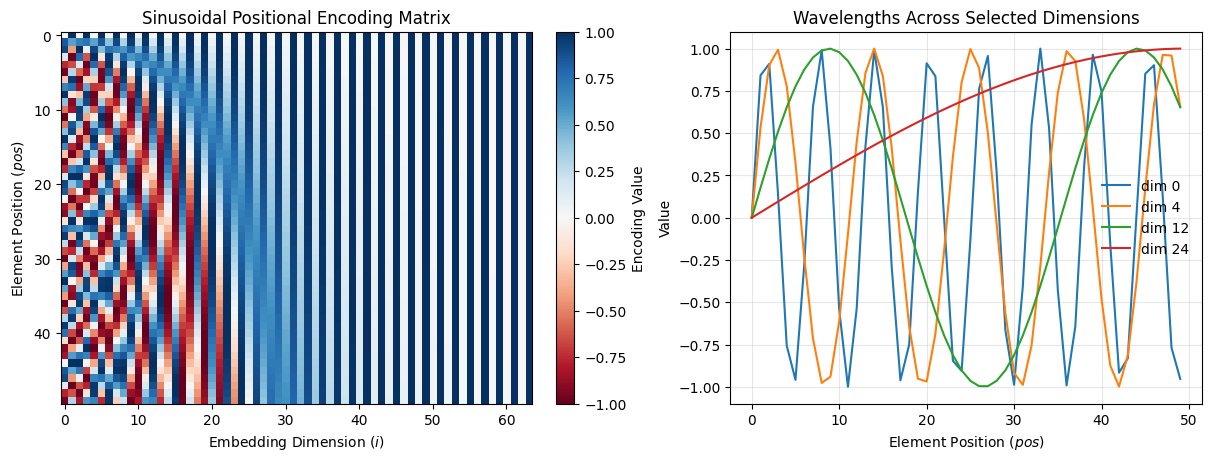

In [ ]:
seq_len = 50
d_model = 64
# for text, vocabulary, for other sequence, consider
# it as the number of unique tokens in the sequence. For example, for DNA sequences, it would be 4 (A, C, G, T). For protein sequences, it would be 20 (the 20 amino acids). For other types of sequences, it could be the number of unique events or symbols in that sequence.
vocab_size = 100

key = jax.random.key(0)
tokens = jnp.arange(seq_len)[None, :]  # (1, seq_len)

# 1. Compute token embeddings
emb_layer = Embedding(vocab_size=vocab_size, d_model=d_model)
emb_vars = emb_layer.init(key, tokens)
emb = emb_layer.apply(emb_vars, tokens)

# 2. Apply positional encoding (training=False disables dropout)
pe_layer = PositionalEncoding(d_model=d_model)
pe_vars = pe_layer.init(key, emb, training=False)
encoded = pe_layer.apply(pe_vars, emb, training=False)

# Isolate the positional encoding matrix: (seq_len, d_model)
pe = np.asarray((encoded - emb)[0])

# 3. Plot heatmap and selected dimension wavelengths
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

im = axes[0].imshow(pe, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
axes[0].set_title("Sinusoidal Positional Encoding Matrix")
axes[0].set_xlabel("Embedding Dimension ($i$)")
axes[0].set_ylabel("Element Position ($pos$)")
fig.colorbar(im, ax=axes[0], label="Encoding Value")

for dim in [0, 4, 12, 24]:
    axes[1].plot(np.arange(seq_len), pe[:, dim], label=f"dim {dim}")
axes[1].set_title("Wavelengths Across Selected Dimensions")
axes[1].set_xlabel("Element Position ($pos$)")
axes[1].set_ylabel("Value")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.3)

plt.show()

The sinusoidal positional encoding matrix $PE \in \mathbb{R}^{T \times d_{\text{model}}}$ assigns a unique $d_{\text{model}}$-dimensional vector to each sequence position $pos \in \{0, \dots, T-1\}$. Each pair of adjacent columns $(2i, 2i+1)$ forms a sine–cosine pair oscillating at a fixed angular frequency $\omega_i = 10000^{-2i / d_{\text{model}}}$.

* **Heatmap (Left):** Displays the full $(T, d_{\text{model}})$ matrix with values bounded in $[-1, 1]$. Dimensions on the left (low $i$) oscillate rapidly across token positions, capturing fine-grained local order. Moving rightward (high $i$), the frequency drops geometrically so that values change very slowly across the sequence, encoding coarse global position—analogous to a continuous binary counter.
* **Selected Dimension Wavelengths (Right):** Isolates individual even (sine) dimensions across sequence positions. As the dimension index increases, the wavelength expands from $2\pi$ at $i = 0$ toward $10000 \cdot 2\pi$ at the highest dimensions, ensuring that no two positions share the same encoding within practical sequence lengths.

### Relative Distance Structure in Positional Encodings

Because self-attention computes inner products between queries and keys, it is useful to examine the dot-product similarity between any two positional encoding vectors $PE_p$ and $PE_q$. Applying the trigonometric identity $\sin(\alpha)\sin(\beta) + \cos(\alpha)\cos(\beta) = \cos(\alpha - \beta)$ to each sine–cosine pair yields:

$$PE_p \cdot PE_q = \sum_{i=0}^{d_{\text{model}}/2 - 1} \cos\!\left(\omega_i (p - q)\right)$$

Crucially, this sum depends only on the **relative offset** $|p - q|$ rather than the absolute positions $p$ and $q$.

* **Dot-Product Similarity Matrix (Left):** Plots $PE \cdot PE^\top \in \mathbb{R}^{T \times T}$. The matrix is symmetric and constant along every diagonal (a Toeplitz structure), confirming that the inner product is strictly shift-invariant. Because $\sin^2(\theta) + \cos^2(\theta) = 1$ for every pair, each vector has a constant squared norm $\|PE_p\|_2^2 = d_{\text{model}} / 2$ (equal to $32$ for $d_{\text{model}} = 64$), forming the bright peak along the main diagonal.
* **Relative Offset Slice (Right):** Takes a single horizontal slice at the centre position and plots similarity against the offset $q - p$. Similarity peaks at offset $0$ and decays symmetrically as tokens move further apart, giving the attention mechanism a smooth, built-in notion of local proximity before training begins.

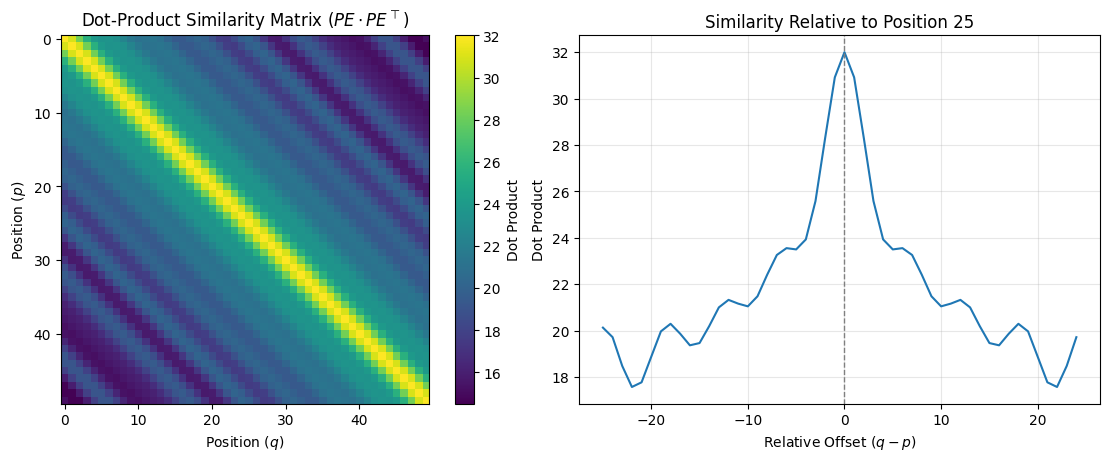

In [ ]:
# Reuse `pe` of shape (seq_len, d_model) from the previous cell
sim = pe @ pe.T  # (seq_len, seq_len)

ref_pos = seq_len // 2
offsets = np.arange(seq_len) - ref_pos

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

# 1. Full dot-product similarity matrix
im = axes[0].imshow(sim, cmap="viridis")
axes[0].set_title(r"Dot-Product Similarity Matrix ($PE \cdot PE^\top$)")
axes[0].set_xlabel("Position ($q$)")
axes[0].set_ylabel("Position ($p$)")
fig.colorbar(im, ax=axes[0], label="Dot Product")

# 2. 1D slice from the centre position showing relative distance decay
axes[1].plot(offsets, sim[ref_pos])
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title(f"Similarity Relative to Position {ref_pos}")
axes[1].set_xlabel("Relative Offset ($q - p$)")
axes[1].set_ylabel("Dot Product")
axes[1].grid(alpha=0.3)

plt.show()

## Transformer

We have to add the Embedding layer in both the Encoder and the Decoder before assembling a `class` for Transformer in code.

In [15]:
class EncoderLayer(nn.Module):
    num_heads: int
    d_model: int
    d_ff: int
    dropout_rate: float = 0.1

    @nn.compact
    def __call__(
        self,
        x: jnp.ndarray,
        src_mask: jnp.ndarray | None = None,
        training: bool = False,
    ) -> jnp.ndarray:
        drop = nn.Dropout(rate=self.dropout_rate, deterministic=not training)

        # 1. Multi-Head Self-Attention + Add & Norm
        attn_out = MultiHeadAttention(self.num_heads, self.d_model, self.dropout_rate)(
            source=x, target=x, mask=src_mask, training=training
        )
        x = nn.LayerNorm()(x + drop(attn_out))

        # 2. Position-wise Feed-Forward Network + Add & Norm
        ffn_out = nn.Dense(self.d_ff)(x)
        ffn_out = nn.relu(ffn_out)
        ffn_out = nn.Dense(self.d_model)(ffn_out)
        x = nn.LayerNorm()(x + drop(ffn_out))

        return x


class Encoder(nn.Module):
    vocab_size: int
    num_layers: int
    num_heads: int
    d_model: int
    d_ff: int
    dropout_rate: float = 0.1

    @nn.compact
    def __call__(
        self,
        src_tokens: jnp.ndarray,
        src_mask: jnp.ndarray | None = None,
        training: bool = False,
    ) -> jnp.ndarray:
        x = Embedding(self.vocab_size, self.d_model)(src_tokens)
        x = PositionalEncoding(self.d_model, self.dropout_rate)(x, training=training)

        for _ in range(self.num_layers):
            x = EncoderLayer(self.num_heads, self.d_model, self.d_ff, self.dropout_rate)(
                x, src_mask=src_mask, training=training
            )
        return x


# -------------


class Decoder(nn.Module):
    vocab_size: int
    num_layers: int
    num_heads: int
    d_model: int
    d_ff: int
    dropout_rate: float = 0.1

    @nn.compact
    def __call__(
        self,
        tgt_tokens: jnp.ndarray,
        enc_output: jnp.ndarray,
        tgt_mask: jnp.ndarray | None = None,
        src_mask: jnp.ndarray | None = None,
        training: bool = False,
    ) -> jnp.ndarray:
        x = Embedding(self.vocab_size, self.d_model)(tgt_tokens)
        x = PositionalEncoding(self.d_model, self.dropout_rate)(x, training=training)

        for _ in range(self.num_layers):
            x = DecoderLayer(self.num_heads, self.d_model, self.d_ff, self.dropout_rate)(
                x, enc_output, tgt_mask=tgt_mask, src_mask=src_mask, training=training
            )
        return x

In [16]:
class Transformer(nn.Module):
    src_vocab_size: int
    tgt_vocab_size: int
    num_layers: int = 6
    num_heads: int = 8
    d_model: int = 512
    d_ff: int = 2048
    dropout_rate: float = 0.1
    pad_id: int = 0

    def setup(self) -> None:
        # Build submodules once so `encode`, `decode`, and `__call__` share the same weights
        self.encoder = Encoder(
            self.src_vocab_size, self.num_layers, self.num_heads,
            self.d_model, self.d_ff, self.dropout_rate
        )
        self.decoder = Decoder(
            self.tgt_vocab_size, self.num_layers, self.num_heads,
            self.d_model, self.d_ff, self.dropout_rate
        )
        # Output projection to vocabulary logits
        self.out_proj = nn.Dense(features=self.tgt_vocab_size)

    def encode(self, src_tokens: jnp.ndarray, src_mask: jnp.ndarray, training: bool = False) -> jnp.ndarray:
        return self.encoder(src_tokens, src_mask=src_mask, training=training)

    def decode(
        self,
        tgt_tokens: jnp.ndarray,
        enc_out: jnp.ndarray,
        src_mask: jnp.ndarray,
        training: bool = False,
    ) -> jnp.ndarray:
        tgt_mask = make_decoder_self_attn_mask(tgt_tokens, self.pad_id)
        dec_out = self.decoder(
            tgt_tokens, enc_out, tgt_mask=tgt_mask, src_mask=src_mask, training=training
        )
        return self.out_proj(dec_out)  # (B, seq_t, tgt_vocab_size)

    def __call__(
        self,
        src_tokens: jnp.ndarray,
        tgt_tokens: jnp.ndarray,
        training: bool = False,
    ) -> jnp.ndarray:
        src_mask = make_padding_mask(src_tokens, self.pad_id)
        enc_out = self.encode(src_tokens, src_mask, training=training)
        return self.decode(tgt_tokens, enc_out, src_mask, training=training)

In [ ]:
key = jax.random.key(42)
params_key, dropout_key = jax.random.split(key)

model = Transformer(
    src_vocab_size=1000,
    tgt_vocab_size=1000,
    num_layers=2,
    num_heads=4,
    d_model=64,
    d_ff=256,
    dropout_rate=0.1,
    pad_id=0,
)

src = jnp.array([[12, 45, 78, 9, 0]])  # (B=1, seq_s=5)
tgt = jnp.array([[1, 34, 88]])         # (B=1, seq_t=3)

variables = model.init(params_key, src, tgt, training=False)
logits = model.apply(variables, src, tgt, training=True, rngs={"dropout": dropout_key})
probs = jax.nn.softmax(logits, axis=-1)

print("Logits shape:", logits.shape)  # (1, 3, 1000)
print("Probabilities sum:", probs[0, 0].sum())  # ~1.0

Logits shape: (1, 3, 1000)
Probabilities sum: 0.9999999


## Generating Text

With the full Transformer defined, we can trace how raw text enters the model and how new text is generated one token at a time.

### Tokenisation

As mentione earlier, a Transformer does not process raw strings directly. Before any computation occurs, a **tokeniser** splits text into discrete units called **tokens** and maps each token to an integer ID in a fixed vocabulary of size $V$.

Modern Transformers typically use **subword tokenisation** (such as Byte-Pair Encoding or SentencePiece) rather than splitting strictly by characters or whole words. Frequent words remain single tokens, while rare or unseen words are broken into known subword pieces—keeping vocabulary size manageable without falling back to unknown-token placeholders. Tokenisers also reserve special control tokens, notably `<BOS>` (beginning of sequence), `<EOS>` (end of sequence), and `<PAD>` (padding).

### Autoregressive Flow Through the Transformer

Text generation is **autoregressive**: the model predicts one token at a time, conditioned on the source input and all tokens it has generated so far.

1. **Encode the source (once):** The source token IDs pass through `Embedding`, `PositionalEncoding`, and the `Encoder` stack to produce contextualised source representations $H_{\text{enc}}$. Because the source sequence does not change during generation, the encoder runs only once.
2. **Decode iteratively:** Generation starts by feeding a single `<BOS>` token into the decoder. At step $t$, the decoder takes the sequence generated so far ($y_{<t}$), applies masked self-attention (so each position attends only to earlier positions), and uses cross-attention to read from $H_{\text{enc}}$.
3. **Extract the next-token state:** The decoder outputs a hidden vector for every position in $y_{<t}$, but only the **final position's vector** $h_t \in \mathbb{R}^{d_{\text{model}}}$ is used to predict token $y_t$.
4. **Append and repeat:** The selected token ID $y_t$ is appended to the decoder input sequence, and the decoder runs again for step $t+1$. This loop terminates when the model emits `<EOS>` or reaches a maximum sequence length.

### Logits and Softmax

At each decoding step, the final linear projection maps $h_t$ to a vector of unnormalised scores—**logits**—across the entire target vocabulary:

$$z = h_t W_{\text{out}} + b_{\text{out}}, \quad z \in \mathbb{R}^{V}$$

Applying the softmax function converts these logits into a valid conditional probability distribution over the next token:

$$P(y_t = v \mid y_{<t}, x) = \frac{\exp(z_v)}{\sum_{j=1}^{V} \exp(z_j)}$$

### Decoding and Sampling Strategies

Converting the probability distribution $P(y_t \mid y_{<t}, x)$ into a concrete token ID is handled by a decoding strategy:

* **Greedy decoding:** Always selects the single highest-probability token, $y_t = \arg\max_v P(y_t = v \mid y_{<t}, x)$. It is fast and deterministic, but often produces repetitive or locally optimal sequences.
* **Temperature scaling ($\tau$):** Rescales the logits before softmax via $z_v / \tau$. Setting $\tau < 1$ sharpens the distribution (concentrating probability mass on the top candidates, approaching greedy decoding as $\tau \to 0$). Setting $\tau > 1$ flattens the distribution, increasing output diversity at the risk of incoherence.
* **Top-$k$ sampling:** Keeps only the $k$ most probable tokens, sets all other probabilities to zero, renormalises the remaining distribution, and samples from it. This prevents the model from sampling implausible tokens from the long low-probability tail.
* **Top-$p$ (nucleus) sampling:** Sorts tokens by descending probability and selects the smallest subset whose cumulative probability exceeds a threshold $p$ (for example, $p = 0.9$), then renormalises and samples. Unlike top-$k$, the candidate pool expands when the model is uncertain and contracts when it is confident.

Once the loop terminates, the generated sequence of token IDs is passed back through the tokeniser to reconstruct human-readable text.

Now let's add the code to get a more practical understanding of text generation. 

In [18]:
def sample_next_token(
    logits: jnp.ndarray,
    key: jax.Array,
    temperature: float = 1.0,
    top_k: int | None = None,
    top_p: float | None = None,
) -> jnp.ndarray:
    """Samples the next token ID from logits of shape (B, vocab_size)."""
    if temperature <= 0.0:
        return jnp.argmax(logits, axis=-1)

    logits = logits / temperature

    if top_k is not None:
        k = min(top_k, logits.shape[-1])  # top_k cannot exceed vocab size
        top_vals, _ = jax.lax.top_k(logits, k=k)
        threshold = top_vals[:, -1:]
        logits = jnp.where(logits < threshold, -jnp.inf, logits)

    if top_p is not None:
        sorted_idx = jnp.argsort(logits, axis=-1)[:, ::-1]
        sorted_logits = jnp.take_along_axis(logits, sorted_idx, axis=-1)
        sorted_probs = jax.nn.softmax(sorted_logits, axis=-1)
        cum_probs = jnp.cumsum(sorted_probs, axis=-1)

        # Keep the first token that pushes cumulative probability above top_p
        remove_mask = (cum_probs - sorted_probs) > top_p
        sorted_logits = jnp.where(remove_mask, -jnp.inf, sorted_logits)

        sampled_pos = jax.random.categorical(key, sorted_logits, axis=-1)
        return jnp.take_along_axis(sorted_idx, sampled_pos[:, None], axis=-1)[:, 0]

    return jax.random.categorical(key, logits, axis=-1)


def generate(
    model: Transformer,
    variables: dict,
    src_tokens: jnp.ndarray,
    bos_id: int = 1,
    eos_id: int = 2,
    max_new_tokens: int = 10,
    key: jax.Array = jax.random.key(99),
    temperature: float = 1.0,
    top_k: int | None = None,
    top_p: float | None = None,
) -> jnp.ndarray:
    """Autoregressively generates target tokens for a single sequence (B=1)."""
    src_mask = make_padding_mask(src_tokens, pad_id=model.pad_id)

    # 1. Encode the source sequence once
    enc_out = model.apply(
        variables, src_tokens, src_mask=src_mask, training=False, method=model.encode
    )

    # 2. Seed the decoder with <BOS>
    tgt_tokens = jnp.array([[bos_id]], dtype=jnp.int32)

    for _ in range(max_new_tokens):
        # 3. Decode the sequence generated so far -> (1, seq_t, tgt_vocab_size)
        logits = model.apply(
            variables,
            tgt_tokens,
            enc_out,
            src_mask=src_mask,
            training=False,
            method=model.decode,
        )

        # 4. Extract logits for the final position -> (1, tgt_vocab_size)
        next_logits = logits[:, -1, :]

        # 5. Sample the next token ID and append it
        key, subkey = jax.random.split(key)
        next_token = sample_next_token(
            next_logits, subkey, temperature=temperature, top_k=top_k, top_p=top_p
        )
        tgt_tokens = jnp.concatenate([tgt_tokens, next_token[:, None]], axis=1)

        if int(next_token[0]) == eos_id:
            break

    return tgt_tokens


gen_key = jax.random.key(100)

greedy_ids = generate(
    model, variables, src, max_new_tokens=8, key=gen_key, temperature=0.0
)
sampled_ids = generate(
    model, variables, src, max_new_tokens=8, key=gen_key,
    temperature=0.8, top_k=50, top_p=0.9,
)

print("Greedy output: ", greedy_ids)
print("Sampled output:", sampled_ids)

Greedy output:  [[  1  15 431 319 319 603 134  54  54]]
Sampled output: [[  1 671 648 672 934 851 428 505 612]]


In the code above, `generate` runs the encoder once on the source sequence and seeds the decoder with a `<BOS>` token. At each step, the decoder processes the tokens generated so far alongside the encoded source. Although it returns logits for every position, only the final position (`logits[:, -1, :]`) is used to predict the next token.

`sample_next_token` then selects the next token ID from those logits. When `temperature <= 0`, it chooses the highest-scoring token deterministically (greedy decoding). Otherwise, it scales the logits by `temperature`, removes low-probability candidates via top-$k$ and top-$p$ filtering, and samples from the remaining distribution. The selected token is appended to the target sequence, and the loop continues until `<EOS>` is emitted or `max_new_tokens` is reached.

Because this model has not been trained, both outputs are arbitrary token IDs. Even so, the difference in behaviour is visible: greedy decoding is deterministic and quickly falls into repetition (`319, 319` and `54, 54`), whereas sampling introduces controlled randomness and produces a more varied sequence.

### Conclusion

We have walked through the complete original Transformer,
from token embeddings and sinusoidal positional encodings through multi head attention, Add & Norm blocks, encoder–decoder cross-attention, and autoregressive text generation. While the original Transformer was aimed at Machine Translation, the modern applications, e.g. LLMs, VLMs etc. adopt different variations of the architecture. For example, instead of  maintaining separate encoder and decoder stacks with cross-attention, most modern LLMs drop the encoder entirely. A single stack of causally masked decoder layers processes both the input prompt and the generated continuation as one unified sequence. Another practical tweak is to use pre layer norm and RMSNorm. Rather applying normalisation after each residual addition (Post-LN), modern models place it *before* each sublayer ($x + \text{Sublayer}(\text{Norm}(x))$. Over time there have been varitions in positional encoding methods as well, i.e. [RoPE](https://arxiv.org/abs/2104.09864).